<a href="https://colab.research.google.com/github/Storm00212/Signals-and-communication-visualisation/blob/main/q5_colab_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Signals & Communication II - Assignment I, Question 5
**Parametric sensitivity study** of Tsys, SNR and G/T for the X-band receiver front-end.

Two architectures are compared everywhere:
- **A (baseline):** Antenna -> Feeder -> LNA
- **B (inverted):** Antenna -> LNA -> Feeder

Rule used throughout: **keep everything linear (kelvin, watts, ratios) while calculating, and only convert to dB at the end.** Temperatures add like powers, and sums cannot be done in dB.

## Cell 1 - Setup: libraries and given specifications

**Why these tools?**
- `numpy` (`np`) gives us *arrays*: a whole list of numbers that we can do maths on in one line (no loops). `np.log10` and `10**x` work on whole arrays at once.
- `matplotlib.pyplot` (`plt`) draws the graphs.
- We store each spec in a named variable (e.g. `T_ant`) so the formulas read like the equations in your notes, and so you can change a spec in one place only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Given specifications (from the assignment) ----------
T_ant      = 200.0     # K    antenna noise temperature
L_nom_dB   = 2.0       # dB   nominal feeder loss
T_phys_nom = 290.0     # K    nominal feeder physical temperature
S_dBm      = -90.0     # dBm  available input signal
G_dB       = 30.0      # dB   LNA gain
F_dB       = 1.5       # dB   LNA noise figure
B          = 10e6      # Hz   equivalent noise bandwidth (10e6 = 10 x 10^6)
T0         = 290.0     # K    standard reference temperature
G_ant_dBi  = 43.6      # dBi  antenna gain
GT_req     = 18.5      # dB/K required figure of merit
k          = 1.380649e-23   # J/K Boltzmann constant

# ---------- Convert dB quantities to LINEAR ratios (done once) ----------
S_W   = 1e-3 * 10**(S_dBm / 10)      # dBm -> W   (1e-3 converts mW to W)
G_lna = 10**(G_dB / 10)              # LNA gain, linear (= 1000)
F_lin = 10**(F_dB / 10)              # noise figure, linear
T_e   = T0 * (F_lin - 1)             # LNA equivalent noise temperature (K)
T_max = 10**((G_ant_dBi - GT_req) / 10)   # largest Tsys that still meets G/T >= 18.5

print(f"Sin   = {S_W:.2e} W")
print(f"G_lna = {G_lna:.0f} (linear)")
print(f"Te    = {T_e:.1f} K")
print(f"Tmax  = {T_max:.1f} K   (G/T requirement  <=>  Tsys <= Tmax)")

Sin   = 1.00e-12 W
G_lna = 1000 (linear)
Te    = 119.6 K
Tmax  = 323.6 K   (G/T requirement  <=>  Tsys <= Tmax)


## Cell 2 - The model: one function per formula

**Why functions?** We need the *same* calculation for many values of L and Tphys. A function is a reusable formula: define it once, call it with a single number or a whole array.

**Why `np.asarray(...)`?** It turns whatever we pass in (a number, a list, an array) into a numpy array, so `10**(x/10)` always works element by element.

The formulas (derived in Q1/Q2/Q4), with L the *linear* loss:
- Baseline: `Tsys = Tant + Tphys(L-1) + L*Te = (Tant - Tphys) + L(Tphys + Te)`
- Inverted: `Tsys = Tant + Te + Tphys(L-1)/G`
- Net gain antenna-plane to output = `G/L` for both orders (same two gains, just multiplied in a different order).
- Output SNR = `Pout / Pn,out` with `Pout = Sin*Gnet` and `Pn,out = k*Tsys*B*Gnet`.
- Figure of merit: `G/T = G_ant - 10 log10(Tsys)`.

In [2]:
def db_to_lin(x_dB):
    """dB -> linear power ratio. Works on a number or a whole array."""
    return 10 ** (np.asarray(x_dB) / 10)

def tsys_baseline(L_dB, T_phys):
    """Antenna -> Feeder -> LNA.  Returns Tsys (K) at the antenna terminals."""
    L = db_to_lin(L_dB)
    return (T_ant - T_phys) + L * (T_phys + T_e)       # form  c + m*x  with x = L

def tsys_inverted(L_dB, T_phys):
    """Antenna -> LNA -> Feeder.  Feeder noise is divided by the LNA gain."""
    L = db_to_lin(L_dB)
    return T_ant + T_e + T_phys * (L - 1) / G_lna

def net_gain(L_dB):
    """Linear gain from antenna plane to receiver input: G / L."""
    return G_lna / db_to_lin(L_dB)

def snr_out_dB(T_sys, L_dB):
    """SNR (dB) at the output: output signal power / output noise power."""
    Gn    = net_gain(L_dB)
    P_out = S_W * Gn                  # W, signal at output
    N_out = k * T_sys * B * Gn        # W, noise at output (N0 = k*Tsys*Gn, times B)
    return 10 * np.log10(P_out / N_out)

def gt_dB(T_sys):
    """Figure of merit G/T in dB/K.  Tsys is converted to dBK with 10*log10."""
    return G_ant_dBi - 10 * np.log10(T_sys)

# Quick sanity check at the nominal point (should match your hand calculation)
for name, f in [("Baseline", tsys_baseline), ("Inverted", tsys_inverted)]:
    T = f(L_nom_dB, T_phys_nom)
    print(f"{name}: Tsys = {float(T):.1f} K | SNR_out = {float(snr_out_dB(T, L_nom_dB)):.2f} dB | G/T = {float(gt_dB(T)):.2f} dB/K")

Baseline: Tsys = 559.2 K | SNR_out = 11.12 dB | G/T = 16.12 dB/K
Inverted: Tsys = 319.8 K | SNR_out = 13.55 dB | G/T = 18.55 dB/K


## Cell 3 - Part 5(a)(i): sweep the feeder loss L from 0.5 to 6.0 dB

**Why `np.linspace(0.5, 6.0, 200)`?** It makes 200 evenly spaced numbers from 0.5 to 6.0 *including both end points*. 200 points is enough for a smooth curve. (`np.arange` also works but can miss the end point because of rounding, so `linspace` is safer when the range is specified by its ends.)

**Why Tphys is held at 290 K here?** A sensitivity study changes **one variable at a time**. For (i) only L moves; Tphys stays at its nominal value.

**Why no loop?** `tsys_baseline(L_dB, T_phys_nom)` receives the whole array and returns a whole array of 200 Tsys values in one go (this is called *vectorisation*).

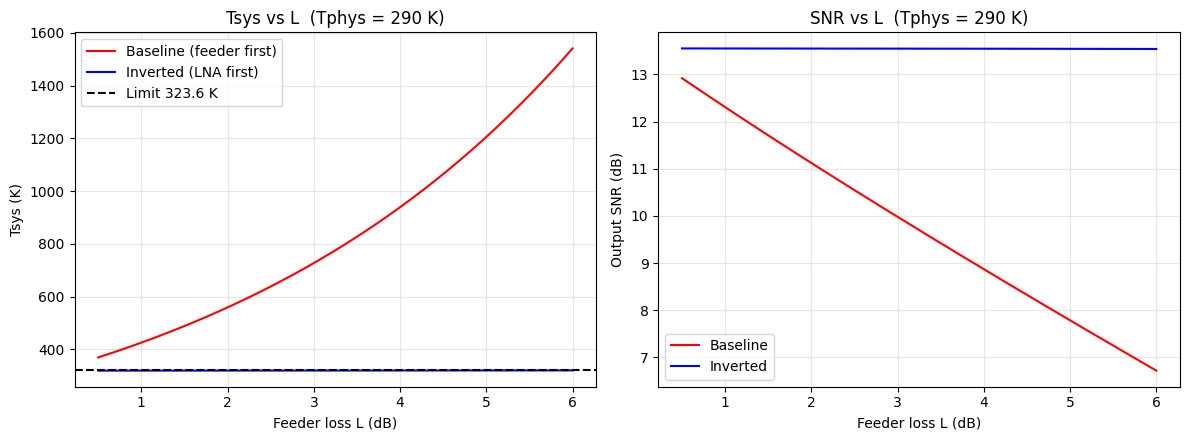

 L (dB) |   Tsys A   SNR A |   Tsys B   SNR B
    0.5 |    369.6   12.92 |    319.7   13.55
    1.0 |    425.7   12.31 |    319.7   13.55
    2.0 |    559.2   11.12 |    319.8   13.55
    3.0 |    727.3    9.98 |    319.9   13.55
    4.0 |    939.0    8.87 |    320.1   13.55
    6.0 |   1540.8    6.72 |    320.5   13.54


In [3]:
L_dB = np.linspace(0.5, 6.0, 200)             # x-axis: feeder loss in dB

Tsys_A_L = tsys_baseline(L_dB, T_phys_nom)    # arrays, same length as L_dB
Tsys_B_L = tsys_inverted(L_dB, T_phys_nom)
SNR_A_L  = snr_out_dB(Tsys_A_L, L_dB)
SNR_B_L  = snr_out_dB(Tsys_B_L, L_dB)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))   # 1 row, 2 plots side by side

ax[0].plot(L_dB, Tsys_A_L, 'r', label='Baseline (feeder first)')
ax[0].plot(L_dB, Tsys_B_L, 'b', label='Inverted (LNA first)')
ax[0].axhline(T_max, color='k', ls='--', label=f'Limit {T_max:.1f} K')
ax[0].set(xlabel='Feeder loss L (dB)', ylabel='Tsys (K)',
          title=f'Tsys vs L  (Tphys = {T_phys_nom:.0f} K)')

ax[1].plot(L_dB, SNR_A_L, 'r', label='Baseline')
ax[1].plot(L_dB, SNR_B_L, 'b', label='Inverted')
ax[1].set(xlabel='Feeder loss L (dB)', ylabel='Output SNR (dB)',
          title=f'SNR vs L  (Tphys = {T_phys_nom:.0f} K)')

for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

# Table at chosen losses (scalar inputs work too, thanks to np.asarray)
print(f"{'L (dB)':>7} | {'Tsys A':>8} {'SNR A':>7} | {'Tsys B':>8} {'SNR B':>7}")
for Lv in [0.5, 1, 2, 3, 4, 6]:
    tA, tB = tsys_baseline(Lv, T_phys_nom), tsys_inverted(Lv, T_phys_nom)
    print(f"{Lv:7.1f} | {float(tA):8.1f} {float(snr_out_dB(tA, Lv)):7.2f} | {float(tB):8.1f} {float(snr_out_dB(tB, Lv)):7.2f}")

## Cell 4 - Part 5(a)(ii): sweep the ambient temperature Tphys from 220 to 340 K

Same idea, now **Tphys moves and L is fixed at 2 dB**. Because Tsys is *linear* in Tphys, both curves will be straight lines; the baseline has a steep slope `(L-1)`, while the inverted slope is `(L-1)/G` (almost flat).

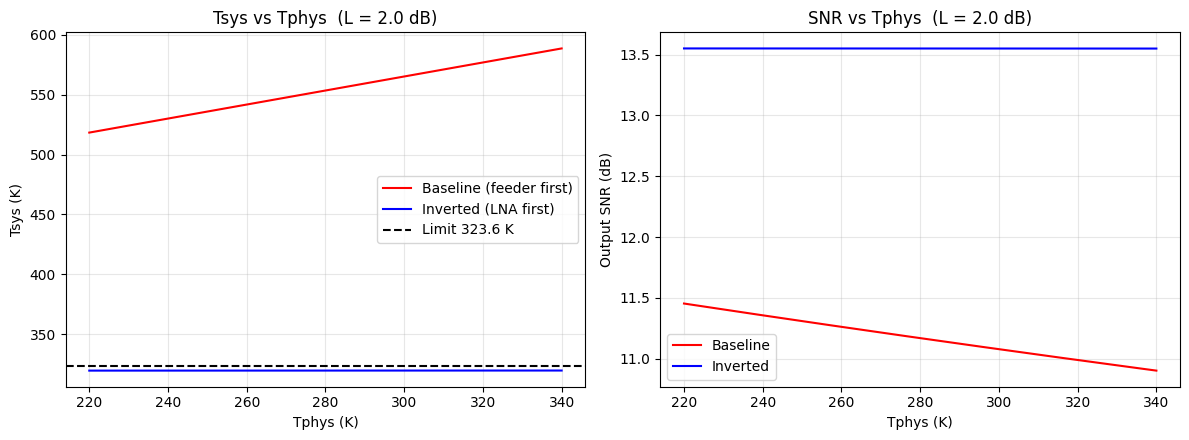

Baseline: Tsys changes by 0.5849 K per K of ambient temperature (70.2 K over the full 220-340 K range)
Inverted: Tsys changes by 0.0006 K per K of ambient temperature (0.1 K over the full 220-340 K range)


In [4]:
T_phys_arr = np.linspace(220, 340, 200)       # x-axis: ambient temperature in K

Tsys_A_T = tsys_baseline(L_nom_dB, T_phys_arr)
Tsys_B_T = tsys_inverted(L_nom_dB, T_phys_arr)
SNR_A_T  = snr_out_dB(Tsys_A_T, L_nom_dB)
SNR_B_T  = snr_out_dB(Tsys_B_T, L_nom_dB)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(T_phys_arr, Tsys_A_T, 'r', label='Baseline (feeder first)')
ax[0].plot(T_phys_arr, Tsys_B_T, 'b', label='Inverted (LNA first)')
ax[0].axhline(T_max, color='k', ls='--', label=f'Limit {T_max:.1f} K')
ax[0].set(xlabel='Tphys (K)', ylabel='Tsys (K)',
          title=f'Tsys vs Tphys  (L = {L_nom_dB} dB)')

ax[1].plot(T_phys_arr, SNR_A_T, 'r', label='Baseline')
ax[1].plot(T_phys_arr, SNR_B_T, 'b', label='Inverted')
ax[1].set(xlabel='Tphys (K)', ylabel='Output SNR (dB)',
          title=f'SNR vs Tphys  (L = {L_nom_dB} dB)')

for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

# Sensitivity = slope. np.polyfit(x, y, 1) fits a straight line and returns [slope, intercept]
for name, T in [("Baseline", Tsys_A_T), ("Inverted", Tsys_B_T)]:
    slope = np.polyfit(T_phys_arr, T, 1)[0]
    print(f"{name}: Tsys changes by {slope:.4f} K per K of ambient temperature "
          f"({slope*(340-220):.1f} K over the full 220-340 K range)")

## Cell 5 - Part 5(b): G/T versus L and versus Tphys, against the 18.5 dB/K requirement

`G/T = 43.6 - 10*log10(Tsys)` is just applied to the Tsys arrays we already have. The requirement is drawn as a **horizontal dashed line**; the curve must stay **above** it.

**Why `axhline`?** It draws a horizontal line across the whole plot at one y value, which is exactly what a fixed specification is.

**Why `fill_between`?** It shades the region where the spec is met, so the pass/fail zone is obvious at a glance.

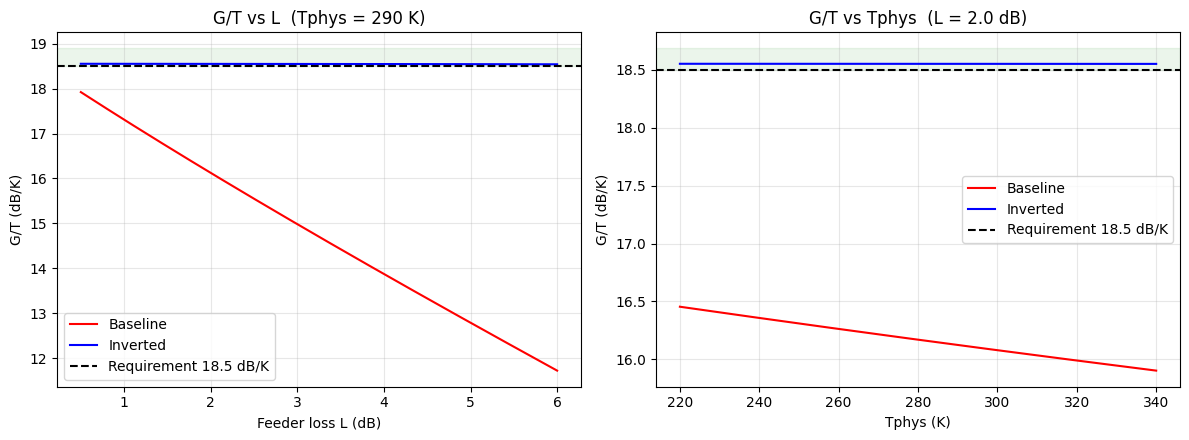

Change in G/T across each sweep (last value minus first value):
  vs L     : Baseline -6.20 dB/K | Inverted -0.011 dB/K
  vs Tphys : Baseline -0.55 dB/K | Inverted -0.0010 dB/K
Lowest G/T in sweep: Baseline 11.72, Inverted 18.54 dB/K


In [5]:
GT_A_L, GT_B_L = gt_dB(Tsys_A_L), gt_dB(Tsys_B_L)
GT_A_T, GT_B_T = gt_dB(Tsys_A_T), gt_dB(Tsys_B_T)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(L_dB, GT_A_L, 'r', label='Baseline')
ax[0].plot(L_dB, GT_B_L, 'b', label='Inverted')
ax[0].set(xlabel='Feeder loss L (dB)', ylabel='G/T (dB/K)',
          title=f'G/T vs L  (Tphys = {T_phys_nom:.0f} K)')

ax[1].plot(T_phys_arr, GT_A_T, 'r', label='Baseline')
ax[1].plot(T_phys_arr, GT_B_T, 'b', label='Inverted')
ax[1].set(xlabel='Tphys (K)', ylabel='G/T (dB/K)',
          title=f'G/T vs Tphys  (L = {L_nom_dB} dB)')

for a in ax:
    a.axhline(GT_req, color='k', ls='--', label=f'Requirement {GT_req} dB/K')
    a.axhspan(GT_req, a.get_ylim()[1], color='green', alpha=0.08)   # pass zone
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

# Quantify the variation: total change across each sweep
print("Change in G/T across each sweep (last value minus first value):")
print(f"  vs L     : Baseline {GT_A_L[-1]-GT_A_L[0]:+.2f} dB/K | Inverted {GT_B_L[-1]-GT_B_L[0]:+.3f} dB/K")
print(f"  vs Tphys : Baseline {GT_A_T[-1]-GT_A_T[0]:+.2f} dB/K | Inverted {GT_B_T[-1]-GT_B_T[0]:+.4f} dB/K")
print(f"Lowest G/T in sweep: Baseline {GT_A_L.min():.2f}, Inverted {GT_B_L.min():.2f} dB/K")

## Cell 6 - Part 5(b): finding the threshold values of L and Tphys

Two methods, so each checks the other.

**Method 1 - Analytic (exact).** Set `Tsys = Tmax = 323.6 K` and solve for the variable:
- Baseline: `L = (Tmax - Tant + Tphys) / (Tphys + Te)` and `Tphys = (Tmax - Tant - L*Te) / (L - 1)`
- Inverted: `L = 1 + G*(Tmax - Tant - Te)/Tphys` and `Tphys = G*(Tmax - Tant - Te)/(L - 1)`

**Method 2 - Scan the simulated curve.** The tools:
- `ok = GT >= 18.5` makes a **boolean array** (True where the spec is met, False otherwise). This is called a *mask*.
- `np.diff(ok.astype(int))` subtracts neighbouring entries; it is non-zero exactly where the mask flips from True to False, i.e. at a crossing.
- `np.where(...)` returns the positions of those non-zero entries.
- We then interpolate linearly between the two points either side of the crossing for a precise value.

If there is no flip, the spec is met everywhere or nowhere in the swept range, and we say so.

In [6]:
def find_crossing(x, y, level):
    """Return the x where curve y crosses 'level' (linear interpolation), or None."""
    ok = y >= level                                   # boolean mask: spec met?
    flips = np.where(np.diff(ok.astype(int)) != 0)[0] # indices where mask changes
    if len(flips) == 0:
        return None
    i = flips[0]
    return x[i] + (level - y[i]) * (x[i+1] - x[i]) / (y[i+1] - y[i])

def report(name, x, y, label):
    if find_crossing(x, y, GT_req) is not None:
        print(f"  {name}: crossing at {label} = {find_crossing(x, y, GT_req):.3f}")
    elif (y >= GT_req).all():
        print(f"  {name}: requirement MET everywhere in the swept range")
    else:
        print(f"  {name}: requirement NEVER met in the swept range")

print("=== Scan method (inside the required ranges) ===")
report("Baseline vs L    ", L_dB, GT_A_L, "L (dB)")
report("Inverted vs L    ", L_dB, GT_B_L, "L (dB)")
report("Baseline vs Tphys", T_phys_arr, GT_A_T, "Tphys (K)")
report("Inverted vs Tphys", T_phys_arr, GT_B_T, "Tphys (K)")

print("\n=== Analytic method (valid even outside the range) ===")
def L_thr_dB_A(Tp): return 10*np.log10((T_max - T_ant + Tp) / (Tp + T_e))
def L_thr_dB_B(Tp): return 10*np.log10(1 + G_lna*(T_max - T_ant - T_e) / Tp)
def Tp_thr_A(L_dB_): L = db_to_lin(L_dB_); return (T_max - T_ant - L*T_e) / (L - 1)
def Tp_thr_B(L_dB_): L = db_to_lin(L_dB_); return G_lna*(T_max - T_ant - T_e) / (L - 1)

for Tp in [220, 290, 340]:
    print(f"Tphys = {Tp} K -> max L: Baseline {L_thr_dB_A(Tp):.3f} dB | Inverted {L_thr_dB_B(Tp):.2f} dB")
for Lv in [0.5, 2.0, 6.0]:
    print(f"L = {Lv} dB -> max Tphys: Baseline {float(Tp_thr_A(Lv)):.0f} K (negative = impossible) | Inverted {float(Tp_thr_B(Lv)):.0f} K")

=== Scan method (inside the required ranges) ===
  Baseline vs L    : requirement NEVER met in the swept range
  Inverted vs L    : requirement MET everywhere in the swept range
  Baseline vs Tphys: requirement NEVER met in the swept range
  Inverted vs Tphys: requirement MET everywhere in the swept range

=== Analytic method (valid even outside the range) ===
Tphys = 220 K -> max L: Baseline 0.050 dB | Inverted 12.79 dB
Tphys = 290 K -> max L: Baseline 0.042 dB | Inverted 11.66 dB
Tphys = 340 K -> max L: Baseline 0.037 dB | Inverted 11.02 dB
L = 0.5 dB -> max Tphys: Baseline -87 K (negative = impossible) | Inverted 32436 K
L = 2.0 dB -> max Tphys: Baseline -113 K (negative = impossible) | Inverted 6767 K
L = 6.0 dB -> max Tphys: Baseline -118 K (negative = impossible) | Inverted 1328 K


## Cell 7 - Part 5(b): turning the thresholds into installation-budget rules

Two ideas, both worth stating in the report:
1. **Even a perfect LNA (Te = 0) cannot rescue a feeder-first design with too much loss**, because the feeder's own noise `Tphys(L-1)` sits directly on top of `Tant`. Setting `Te = 0` gives the loss ceiling `L <= 1 + (Tmax - Tant)/Tphys`.
2. **In the inverted design the real budget is the LNA noise temperature**: the feeder is almost free, so the only thing standing between 319.8 K and the 323.6 K limit is `Te`. The largest allowed `Te` gives a **maximum noise figure**, `NF = 10*log10(1 + Te/T0)`.

In [7]:
print("=== Rule 1: feeder-first, even with an IDEAL (noiseless) LNA ===")
for Tp in [220, 290, 340]:
    L_max = 1 + (T_max - T_ant) / Tp
    print(f"  Tphys = {Tp} K -> L must be <= {10*np.log10(L_max):.2f} dB")

print("\n=== Rule 2: inverted architecture margin ===")
T_nom_B = float(tsys_inverted(L_nom_dB, T_phys_nom))
print(f"  Nominal Tsys = {T_nom_B:.1f} K, margin to limit = {T_max - T_nom_B:.1f} K "
      f"(= {float(gt_dB(T_nom_B)) - GT_req:.2f} dB/K of G/T)")
Te_max   = T_max - T_ant                    # feeder contribution ~ 0 here
NF_max   = 10*np.log10(1 + Te_max / T0)
print(f"  Largest allowed LNA Te ~ {Te_max:.1f} K  ->  NF must be <= {NF_max:.2f} dB (spec uses {F_dB} dB)")
for Tp in [220, 290, 340]:
    print(f"  Tphys = {Tp} K -> feeder loss may reach {L_thr_dB_B(Tp):.1f} dB before failing")

print("\n=== Rule of thumb: thermal margin ===")
print(f"  Baseline: each +10 K of ambient adds {10*(float(db_to_lin(L_nom_dB))-1):.1f} K to Tsys")
print(f"  Inverted: each +10 K of ambient adds {10*(float(db_to_lin(L_nom_dB))-1)/G_lna:.4f} K to Tsys")

=== Rule 1: feeder-first, even with an IDEAL (noiseless) LNA ===
  Tphys = 220 K -> L must be <= 1.94 dB
  Tphys = 290 K -> L must be <= 1.54 dB
  Tphys = 340 K -> L must be <= 1.35 dB

=== Rule 2: inverted architecture margin ===
  Nominal Tsys = 319.8 K, margin to limit = 3.8 K (= 0.05 dB/K of G/T)
  Largest allowed LNA Te ~ 123.6 K  ->  NF must be <= 1.54 dB (spec uses 1.5 dB)
  Tphys = 220 K -> feeder loss may reach 12.8 dB before failing
  Tphys = 290 K -> feeder loss may reach 11.7 dB before failing
  Tphys = 340 K -> feeder loss may reach 11.0 dB before failing

=== Rule of thumb: thermal margin ===
  Baseline: each +10 K of ambient adds 5.8 K to Tsys
  Inverted: each +10 K of ambient adds 0.0058 K to Tsys


## Cell 8 (optional) - 2-D map of G/T over both variables at once

**Why `np.meshgrid`?** It turns two 1-D lists (L values and Tphys values) into two 2-D grids so that every combination of (L, Tphys) is evaluated. Our functions then compute a whole *surface* of G/T in one call, and `contourf` colours it. A red contour marks 18.5 dB/K if the requirement boundary crosses the plotted region.

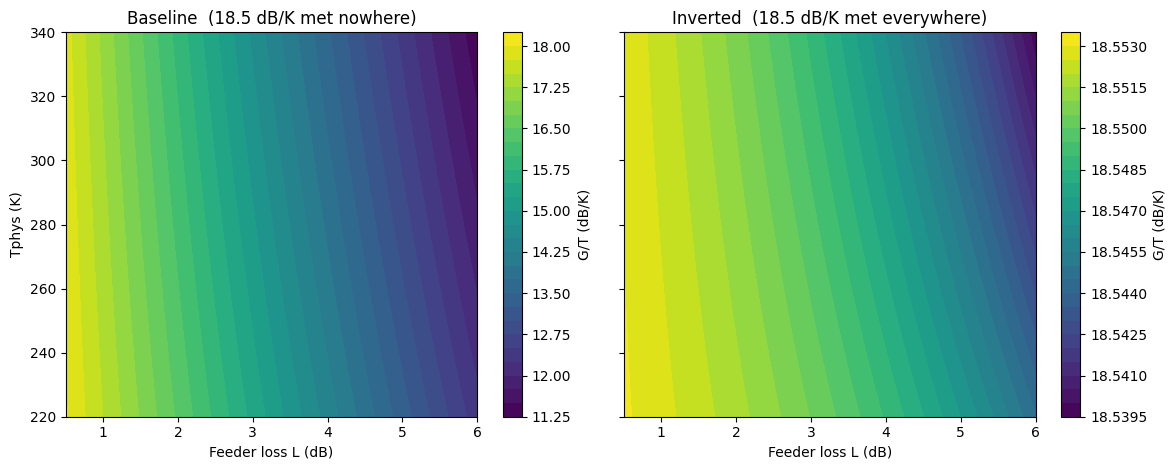

In [8]:
LL, TT = np.meshgrid(np.linspace(0.5, 6.0, 120), np.linspace(220, 340, 120))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for a, (name, f) in zip(axs, [("Baseline", tsys_baseline), ("Inverted", tsys_inverted)]):
    GT = gt_dB(f(LL, TT))                       # whole 2-D grid at once
    cs = a.contourf(LL, TT, GT, 30, cmap='viridis')
    fig.colorbar(cs, ax=a, label='G/T (dB/K)')
    if GT.min() < GT_req < GT.max():
        a.contour(LL, TT, GT, levels=[GT_req], colors='r', linewidths=2)
        note = "red line = 18.5 dB/K"
    else:
        note = "18.5 dB/K met everywhere" if GT.min() >= GT_req else "18.5 dB/K met nowhere"
    a.set(xlabel='Feeder loss L (dB)', title=f'{name}  ({note})')
axs[0].set_ylabel('Tphys (K)')
plt.tight_layout(); plt.show()